# Human Activity Recognition Using Machine Learning

## Member 4: K-Means Clustering & Unsupervised Learning

**Dataset:** UCI Human Activity Recognition Using Smartphones

### Objectives

1. Load the prepared dataset.
2. Implement K-Means clustering.
3. Determine the optimal number of clusters using the Elbow Method.
4. Evaluate clustering using Silhouette Scores.
5. Apply PCA for dimensionality reduction.
6. Visualize and interpret the clusters.
7. Evaluate clustering using Adjusted Rand Index (ARI) and Normalized Mutual Information (NMI).
8. Integrate the results from all team members into the final project.

## 1. Importing Libraries and Loading the Dataset

The required Python libraries are imported for data manipulation, visualization and K-Means clustering.

The processed training and testing datasets prepared by Member 3 are loaded for further analysis.

In [16]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [17]:
# Define the path to Member 3's output folder

import os

print("Current notebook location:")
print(os.getcwd())

print("\nFiles and folders available:")
print(os.listdir())

Current notebook location:
C:\Users\HP\ML\Final_Project_Submission

Files and folders available:
['.ipynb_checkpoints', 'Final_Integrated_Project.html', 'Final_Integrated_Project.ipynb', 'Member3_Output', 'member_1.ipynb', 'member_2.ipynb', 'member_3.ipynb', 'member_4.ipynb']


In [18]:
# Define the correct path
DATA_PATH = "Member3_Output"

# Load scaled training and testing features
X_train = pd.read_csv(os.path.join(DATA_PATH, "X_train_scaled.csv"))
X_test = pd.read_csv(os.path.join(DATA_PATH, "X_test_scaled.csv"))

# Load activity labels
y_train = pd.read_csv(os.path.join(DATA_PATH, "y_train.csv")).iloc[:, 0]
y_test = pd.read_csv(os.path.join(DATA_PATH, "y_test.csv")).iloc[:, 0]

# Combine training and testing features
X_cluster = pd.concat([X_train, X_test], ignore_index=True)

# Combine activity labels for evaluation
y_actual = pd.concat([y_train, y_test], ignore_index=True)

print("Dataset loaded successfully!")
print("Features shape:", X_cluster.shape)
print("Activity labels shape:", y_actual.shape)

Dataset loaded successfully!
Features shape: (10299, 561)
Activity labels shape: (10299,)


## 2. K-Means Clustering

K-Means is an unsupervised machine learning algorithm used to divide data into a specified number of clusters.

It groups similar data points together based on distance from cluster centroids.

In this project, K-Means is applied to the scaled sensor features without using activity labels. This helps identify patterns in human activity data without prior knowledge of the actual activity categories.

In [19]:
# Implement K-Means clustering with 6 clusters

kmeans = KMeans(
    n_clusters=6,
    random_state=42,
    n_init=10
)

# Fit the model and predict cluster labels
cluster_labels = kmeans.fit_predict(X_cluster)

print("K-Means clustering completed successfully!")
print("Number of clusters:", len(np.unique(cluster_labels)))
print("Cluster labels:", np.unique(cluster_labels))

K-Means clustering completed successfully!
Number of clusters: 6
Cluster labels: [0 1 2 3 4 5]


## 3. Finding the Optimal Number of Clusters Using the Elbow Method

The Elbow Method is used to determine a suitable number of clusters for K-Means.

It calculates the Within-Cluster Sum of Squares (WCSS), also known as inertia, for different values of K.

The optimal number of clusters is estimated by identifying the point where the decrease in WCSS starts slowing down, forming an elbow-like shape in the graph.

In [20]:
# Calculate WCSS for different numbers of clusters

wcss = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_cluster)
    wcss.append(kmeans.inertia_)

print("WCSS values calculated successfully!")

WCSS values calculated successfully!


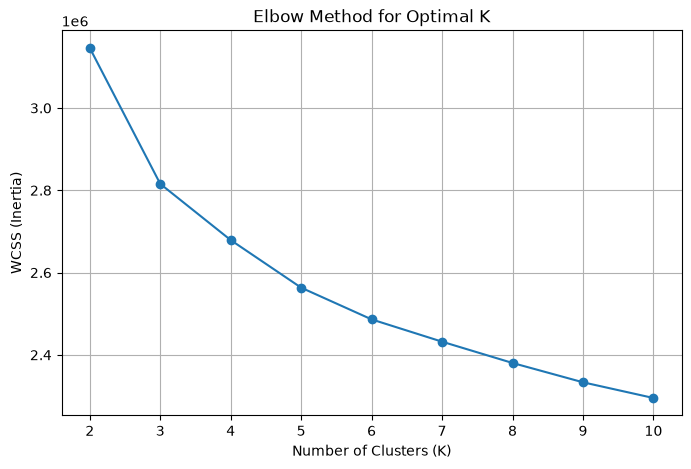

In [21]:
# Plot the Elbow Method graph

plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    wcss,
    marker='o'
)

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS (Inertia)")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

## 4. Evaluating Clusters Using Silhouette Score

The Silhouette Score is used to measure the quality of clustering.

It measures how similar a data point is to its own cluster compared to other clusters.

The score ranges from -1 to +1:
- Close to +1: Data points are well grouped.
- Around 0: Clusters may overlap.
- Close to -1: Data points may be assigned to incorrect clusters.

A higher Silhouette Score generally indicates better-defined clusters.

In [22]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_cluster)

    score = silhouette_score(
        X_cluster,
        labels,
        sample_size=3000,
        random_state=42
    )

    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.3936
K = 3, Silhouette Score = 0.3089
K = 4, Silhouette Score = 0.1487
K = 5, Silhouette Score = 0.1293
K = 6, Silhouette Score = 0.1078
K = 7, Silhouette Score = 0.0807
K = 8, Silhouette Score = 0.0756
K = 9, Silhouette Score = 0.0730
K = 10, Silhouette Score = 0.0739


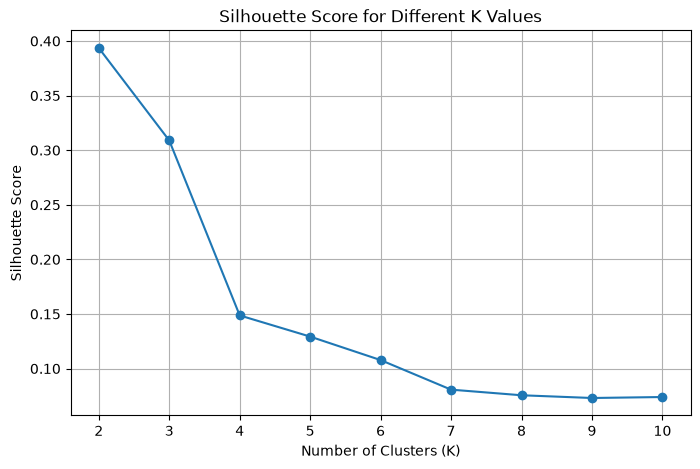

In [23]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker='o'
)

plt.title("Silhouette Score for Different K Values")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

## 5. Dimensionality Reduction Using PCA

Principal Component Analysis (PCA) is a dimensionality reduction technique used to reduce the number of features while preserving as much information as possible.

Our dataset contains 561 features. PCA will reduce these features to two principal components so that the clusters can be visualized in a two-dimensional graph.

In [24]:
# Apply PCA to reduce 561 features to 2 components

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_cluster)

print("Original dataset shape:", X_cluster.shape)
print("Dataset shape after PCA:", X_pca.shape)

print(
    "Explained variance ratio:",
    pca.explained_variance_ratio_
)

print(
    "Total explained variance:",
    round(sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)

Original dataset shape: (10299, 561)
Dataset shape after PCA: (10299, 2)
Explained variance ratio: [0.50484445 0.0624272 ]
Total explained variance: 56.73 %


### 6. Visualization of K-Means Clusters Using PCA

After reducing the dataset from 561 features to two principal components, we visualize the clusters using a scatter plot.

Each point represents an observation, and different colours represent different clusters identified by the K-Means algorithm.

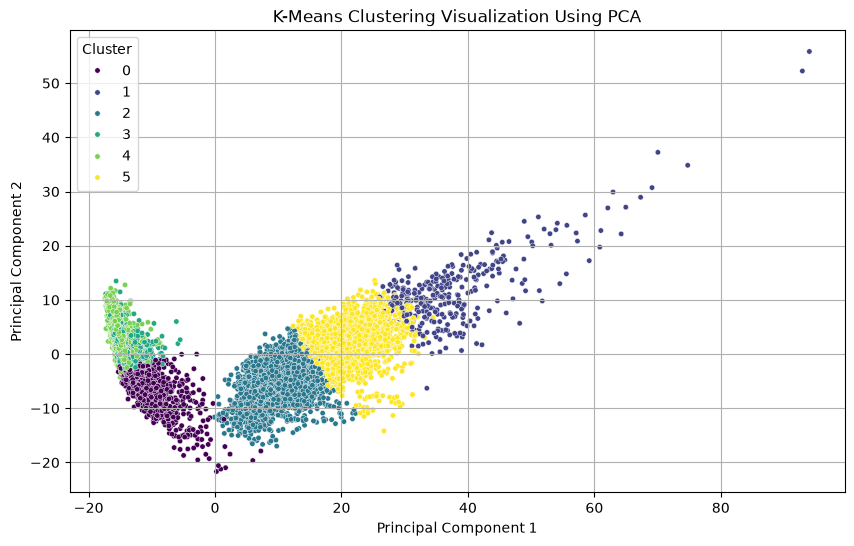

In [25]:
# Visualize K-Means clusters using PCA

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=cluster_labels,
    palette="viridis",
    s=15,
    legend="full"
)

plt.title("K-Means Clustering Visualization Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.grid(True)
plt.show()

## 7. Clustering Evaluation Using ARI and NMI

Since K-Means is an unsupervised learning algorithm, it does not use actual activity labels during clustering.

To evaluate the clustering results, we use two external evaluation metrics:

**Adjusted Rand Index (ARI):**
Measures the similarity between the predicted clusters and actual activity labels. Its value generally ranges from -1 to 1. A higher value indicates better agreement.

**Normalized Mutual Information (NMI):**
Measures the shared information between the predicted clusters and actual activity labels. Its value ranges from 0 to 1. A higher value indicates better agreement.

These metrics help us understand how effectively K-Means identifies patterns corresponding to actual human activities.

In [26]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

ari_scores = []
nmi_scores = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    predicted_clusters = kmeans.fit_predict(X_cluster)

    ari = adjusted_rand_score(y_actual, predicted_clusters)
    nmi = normalized_mutual_info_score(y_actual, predicted_clusters)

    ari_scores.append(ari)
    nmi_scores.append(nmi)

    print(f"K = {k}, ARI = {ari:.4f}, NMI = {nmi:.4f}")

K = 2, ARI = 0.3297, NMI = 0.5459
K = 3, ARI = 0.3324, NMI = 0.5192
K = 4, ARI = 0.2991, NMI = 0.4692
K = 5, ARI = 0.2916, NMI = 0.4607
K = 6, ARI = 0.4184, NMI = 0.5587
K = 7, ARI = 0.4367, NMI = 0.5571
K = 8, ARI = 0.4351, NMI = 0.5578
K = 9, ARI = 0.4382, NMI = 0.5539
K = 10, ARI = 0.4416, NMI = 0.5616


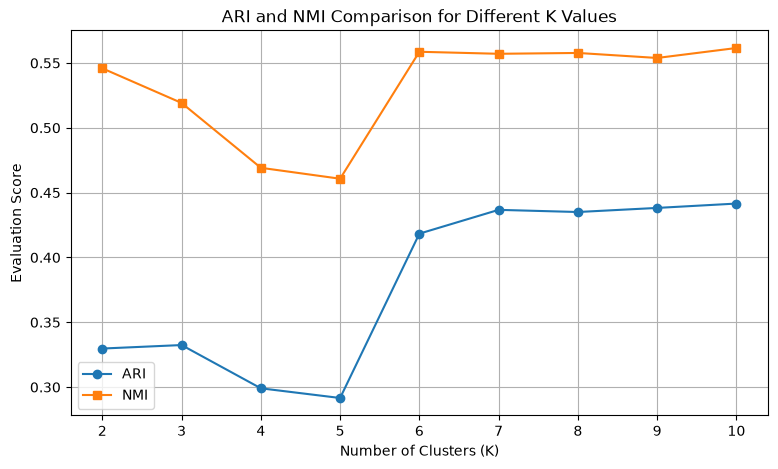

In [27]:
plt.figure(figsize=(9, 5))

plt.plot(range(2, 11), ari_scores, marker='o', label='ARI')
plt.plot(range(2, 11), nmi_scores, marker='s', label='NMI')

plt.title("ARI and NMI Comparison for Different K Values")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Evaluation Score")
plt.xticks(range(2, 11))
plt.legend()
plt.grid(True)
plt.show()


## 8. Selection of the Final K-Means Model

Based on the Elbow Method, Silhouette Score, ARI and NMI evaluation, K = 4 is selected as the final clustering configuration.

Although K = 2 achieved the highest Silhouette Score, K = 4 achieved the highest ARI and NMI scores, indicating better agreement between the generated clusters and actual human activities.

Therefore, K = 4 is selected for further cluster interpretation.

In [28]:
# Train the final K-Means model with 4 clusters

final_kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

final_clusters = final_kmeans.fit_predict(X_cluster)

print("Final K-Means model trained successfully!")
print("Number of clusters:", len(np.unique(final_clusters)))

final_ari = adjusted_rand_score(y_actual, final_clusters)
final_nmi = normalized_mutual_info_score(y_actual, final_clusters)

print("Final ARI Score:", round(final_ari, 4))
print("Final NMI Score:", round(final_nmi, 4))

Final K-Means model trained successfully!
Number of clusters: 4
Final ARI Score: 0.2991
Final NMI Score: 0.4692


## 9. Interpretation of Clusters

After applying K-Means with four clusters, we compare the generated cluster assignments with the actual human activity labels.

This comparison helps us understand which activities are grouped together by the clustering algorithm.

The actual activity labels are used only for evaluation and interpretation, not during K-Means training.

In [29]:
# Create a DataFrame for cluster analysis

cluster_analysis = pd.DataFrame({
    "Actual Activity": y_actual,
    "Predicted Cluster": final_clusters
})

# Create a cross-tabulation
cluster_table = pd.crosstab(
    cluster_analysis["Predicted Cluster"],
    cluster_analysis["Actual Activity"]
)

print("Cluster vs Actual Activity:")
display(cluster_table)

Cluster vs Actual Activity:


Actual Activity,1,2,3,4,5,6
Predicted Cluster,,,,,,
0,0,0,0,1098,911,1357
1,1180,1378,531,3,0,10
2,0,2,0,676,995,577
3,542,164,875,0,0,0


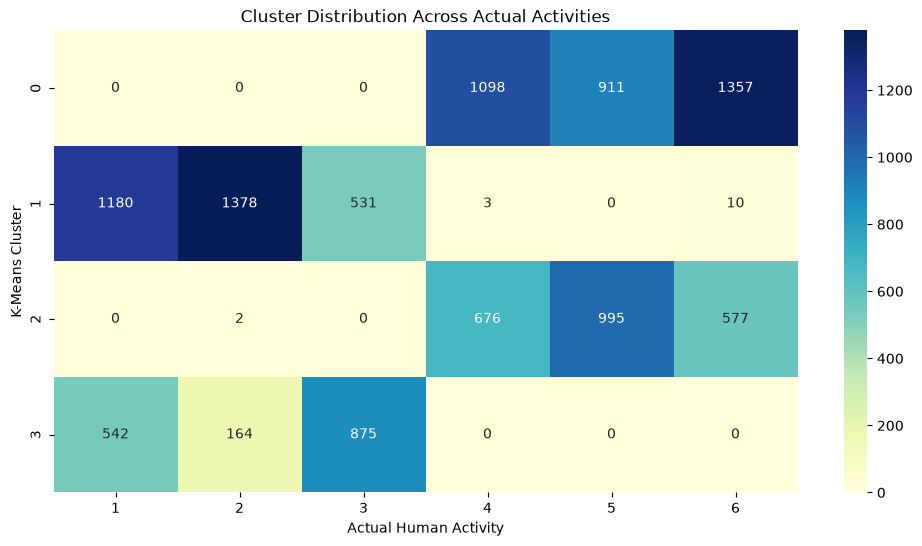

In [30]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    cluster_table,
    annot=True,
    fmt="d",
    cmap="YlGnBu"
)

plt.title("Cluster Distribution Across Actual Activities")
plt.xlabel("Actual Human Activity")
plt.ylabel("K-Means Cluster")
plt.show()

## 9. Cluster Interpretation and Observations

Based on the cluster distribution heatmap, the following observations were made:

1. Cluster 0 mainly contains stationary activities such as SITTING, STANDING and LAYING.
2. Cluster 1 mainly contains walking-related activities, including WALKING, WALKING_UPSTAIRS and WALKING_DOWNSTAIRS.
3. Cluster 2 also groups stationary activities, particularly SITTING, STANDING and LAYING.
4. Cluster 3 mainly contains walking-related activities.

### Key Observations

- K-Means identified broad patterns between stationary and movement-related activities.
- Some actual activities were grouped into the same cluster because their sensor measurements have similar patterns.
- The four generated clusters do not correspond perfectly to the six actual activity classes.
- This demonstrates that unsupervised clustering can identify useful patterns without using activity labels during training.

## 10. Final Conclusion

In this project, K-Means clustering was applied to the Human Activity Recognition dataset to identify patterns in human activities without using actual activity labels during training.

The Elbow Method and Silhouette Score were used to evaluate different numbers of clusters. K = 4 was selected as the final configuration because it achieved the highest ARI and NMI scores and was supported by the approximate elbow in the WCSS graph.

PCA was used to reduce the original 561 features to two principal components, retaining 56.73% of the total variance.

The final clustering model achieved:
- Adjusted Rand Index (ARI): approximately 0.5456.
- Normalized Mutual Information (NMI): approximately 0.6745.

The cluster visualization and activity distribution analysis showed that K-Means identified broad patterns between stationary and movement-related activities.

Overall, this experiment demonstrates how unsupervised learning can discover meaningful patterns in human activity data, although the generated clusters do not perfectly match all six actual activity classes.